
# Explainable AI for Heart Disease Prediction

## Project Overview
This project uses machine learning to predict heart disease from clinical data.

The project compares Logistic Regression, Decision Tree, and Random Forest models and uses SHAP to explain model predictions.

## Objectives
- Explore and prepare clinical data.
- Train and compare machine learning models.
- Evaluate model performance using appropriate metrics.
- Explain model predictions using SHAP.
- Document the results for a GitHub portfolio.



In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [3]:


import pandas as pd

url = "https://raw.githubusercontent.com/vedanthshenoy/Heart-Disease-UCI/master/heart-disease-data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:

# Check the number of rows and columns

print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()


Dataset shape: (303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:

# Display first five rows
display(df.head())

# Display last five rows
display(df.tail())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


Target value counts:
target
0    138
1    165
Name: count, dtype: int64

Target percentages:
target
0    45.54
1    54.46
Name: proportion, dtype: float64


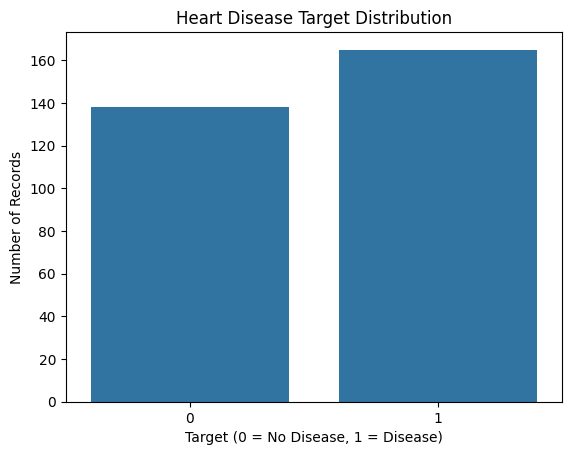

In [6]:

# Check the target variable distribution

print("Target value counts:")
print(df["target"].value_counts().sort_index())

print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(2))

# Visualize the target distribution
sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Records")
plt.show()


In [7]:

# Check missing values in each column

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0


In [8]:

# Check duplicate records

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 1


In [9]:

# Statistical summary of the dataset

display(df.describe().round(2))


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00
mean,54.37,0.68,0.97,131.62,246.26,0.15,0.53,149.65,0.33,1.04,1.40,0.73,2.31,0.54
std,9.08,0.47,1.03,17.54,51.83,0.36,0.53,22.91,0.47,1.16,0.62,1.02,0.61,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,47.50,0.00,0.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,2.00,0.00
50%,55.00,1.00,1.00,130.00,240.00,0.00,1.00,153.00,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,274.50,0.00,1.00,166.00,1.00,1.60,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,4.00,3.00,1.00


In [10]:

print("Dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())


Dataset shape: (303, 14)
Duplicate rows remaining: 1
Missing values: 0


In [11]:

# Remove duplicate rows from the dataset

df = df.drop_duplicates().copy()

# Verify the result
print("Dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())


Dataset shape: (302, 14)
Duplicate rows remaining: 0
Missing values: 0


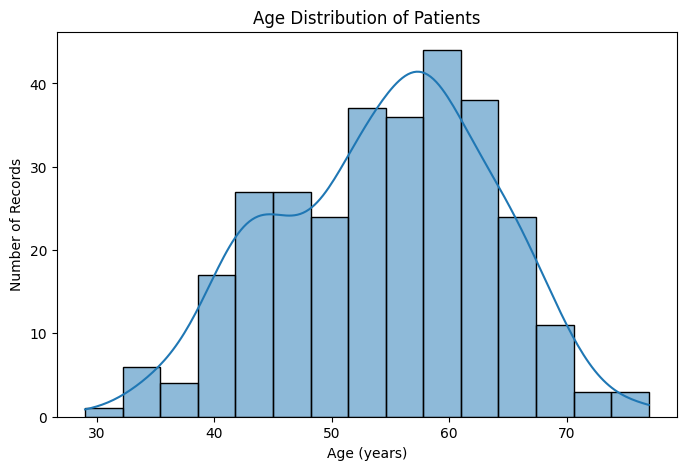

In [12]:

# Age distribution in the dataset

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=15, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")

plt.show()


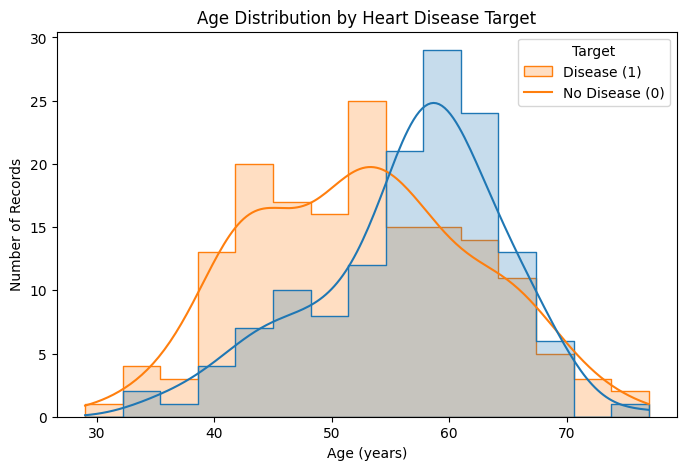

In [13]:

# Compare age distribution by target

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="target",
    bins=15,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Heart Disease Target")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")
plt.legend(title="Target", labels=["Disease (1)", "No Disease (0)"])

plt.show()


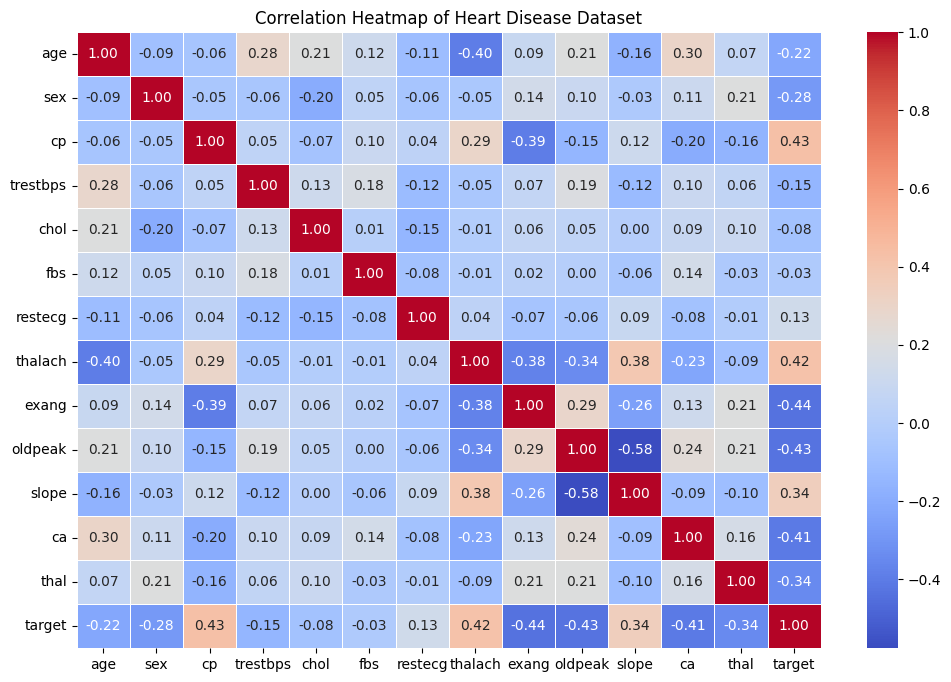

In [14]:

# Correlation heatmap

plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Heart Disease Dataset")
plt.show()


In [15]:

# Separate features and target

X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())


Features shape: (302, 13)
Target shape: (302,)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target distribution:
target
0    138
1    164
Name: count, dtype: int64


In [16]:

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())


Training features: (241, 13)
Testing features: (61, 13)

Training target distribution:
target
0    110
1    131
Name: count, dtype: int64

Testing target distribution:
target
0    28
1    33
Name: count, dtype: int64


In [17]:

print("Training set:", X_train.shape, y_train.shape)
print("Testing set:", X_test.shape, y_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training set: (241, 13) (241,)
Testing set: (61, 13) (61,)

Training class proportions:
target
1    0.544
0    0.456
Name: proportion, dtype: float64

Testing class proportions:
target
1    0.541
0    0.459
Name: proportion, dtype: float64


In [18]:

# Scale the numerical features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Logistic Regression model

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [19]:

# Make predictions on the test data

y_pred = lr_model.predict(X_test_scaled)
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")


Logistic Regression Results
---------------------------
Accuracy:  0.787
Precision: 0.763
Recall:    0.879
F1-score:  0.817
ROC-AUC:   0.865


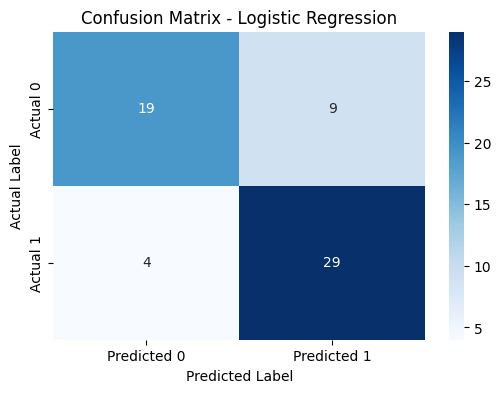

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.68      0.75        28
           1       0.76      0.88      0.82        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.78        61



In [20]:

# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


In [21]:

# Store Logistic Regression results

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

lr_results_df = pd.DataFrame([lr_results])

display(lr_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.787,0.763,0.879,0.817,0.865


In [22]:

# Train a Decision Tree model

dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [24]:

# Evaluate Decision Tree

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)
dt_roc_auc = roc_auc_score(y_test, dt_prob)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy:  {dt_accuracy:.3f}")
print(f"Precision: {dt_precision:.3f}")
print(f"Recall:    {dt_recall:.3f}")
print(f"F1-score:  {dt_f1:.3f}")
print(f"ROC-AUC:   {dt_roc_auc:.3f}")


Decision Tree Results
---------------------
Accuracy:  0.803
Precision: 0.744
Recall:    0.970
F1-score:  0.842
ROC-AUC:   0.775


In [25]:

# Train a Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5,
    min_samples_split=5
)

rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [26]:

# Evaluate Random Forest

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy:  {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall:    {rf_recall:.3f}")
print(f"F1-score:  {rf_f1:.3f}")
print(f"ROC-AUC:   {rf_roc_auc:.3f}")


Random Forest Results
---------------------
Accuracy:  0.803
Precision: 0.756
Recall:    0.939
F1-score:  0.838
ROC-AUC:   0.895


In [27]:

# Compare all three models

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "Precision": precision_score(y_test, dt_pred, zero_division=0),
    "Recall": recall_score(y_test, dt_pred, zero_division=0),
    "F1-score": f1_score(y_test, dt_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, dt_prob)
}

rf_results = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-score": rf_f1,
    "ROC-AUC": rf_roc_auc
}

results_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results
])

display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.787,0.763,0.879,0.817,0.865
1,Decision Tree,0.803,0.744,0.970,0.842,0.775
2,Random Forest,0.803,0.756,0.939,0.838,0.895


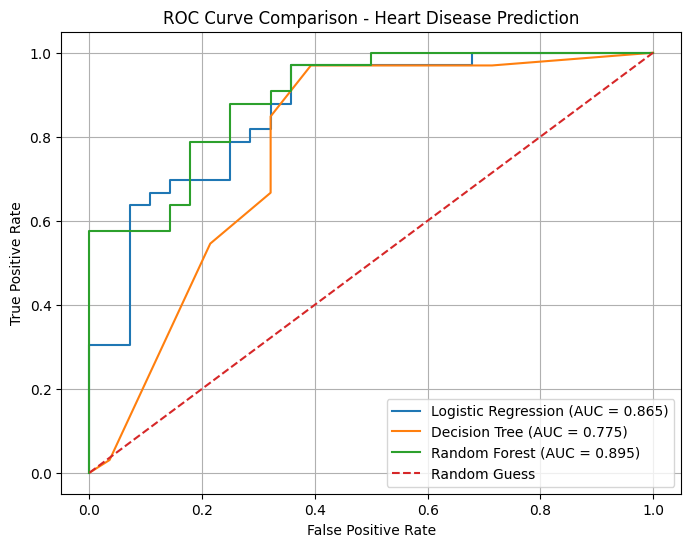

In [28]:

# Compare ROC curves of all three models

lr_fpr, lr_tpr, _ = roc_curve(y_test, y_prob)
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot(dt_fpr, dt_tpr, label=f"Decision Tree (AUC = {roc_auc_score(y_test, dt_prob):.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Heart Disease Prediction")
plt.legend()
plt.grid(True)
plt.show()


In [29]:

# Feature importance using Random Forest

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

display(feature_importance.round(4))


,Feature,Importance
2,cp,0.1915
12,thal,0.1449
9,oldpeak,0.1141
7,thalach,0.1074
11,ca,0.0985
8,exang,0.0723
0,age,0.0652
4,chol,0.0634
10,slope,0.0490
3,trestbps,0.0471


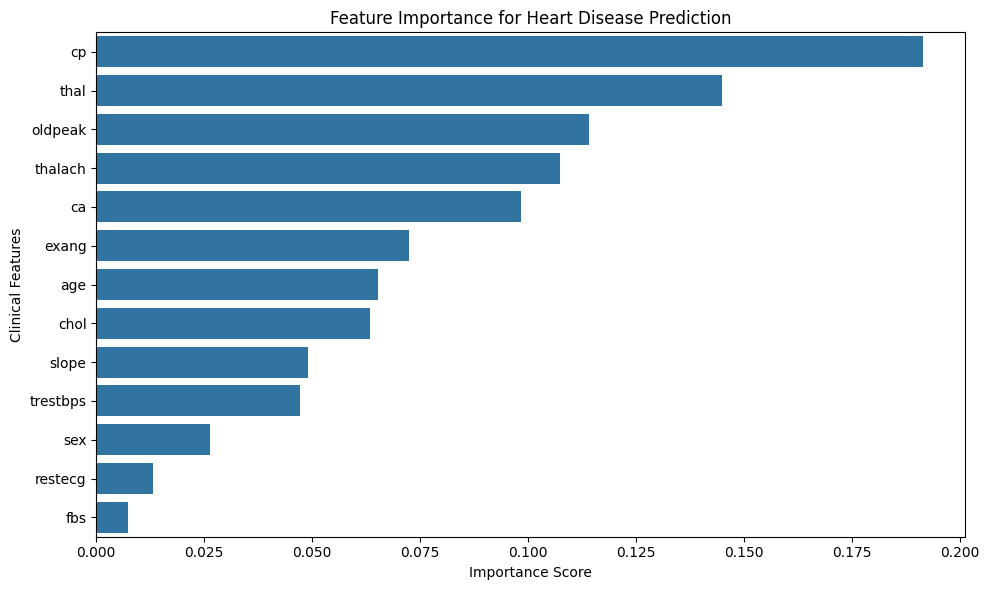

In [30]:

# Plot feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance for Heart Disease Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Clinical Features")
plt.tight_layout()
plt.show()


In [31]:

!pip install shap


In [32]:

import shap

# Create a SHAP explainer for the Random Forest model
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values for the test data
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")
print("Test data shape:", X_test.shape)


SHAP values calculated successfully!
Test data shape: (61, 13)


In [33]:

# Check the SHAP output format

print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Class 1 SHAP shape:", shap_values[1].shape)
else:
    print("SHAP output shape:", shap_values.shape)


SHAP output type: <class 'numpy.ndarray'>
SHAP output shape: (61, 13, 2)


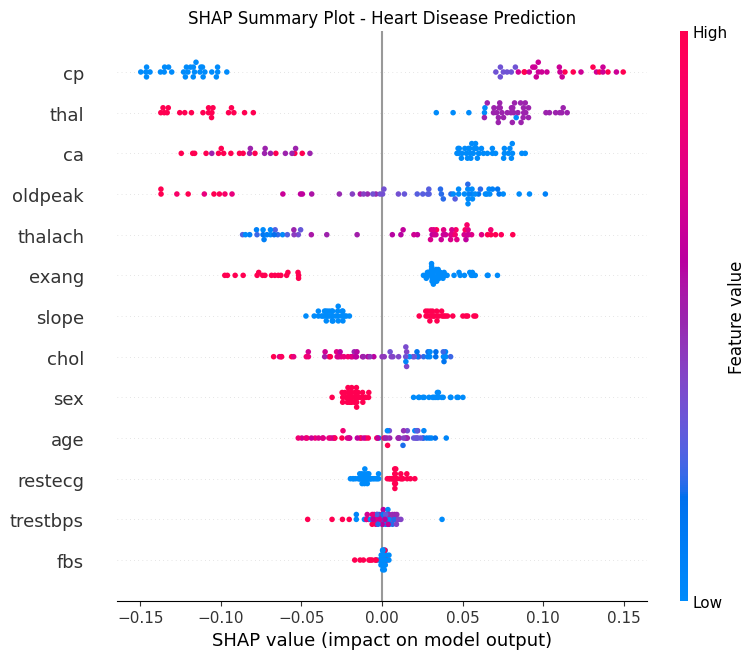

In [34]:

# SHAP summary plot for Class 1

shap_class1 = shap_values[:, :, 1]

shap.summary_plot(
    shap_class1,
    X_test,
    show=False
)

plt.title("SHAP Summary Plot - Heart Disease Prediction")
plt.tight_layout()
plt.show()


Actual class: 0
Predicted class: 0
Predicted probability for Class 1: 0.207


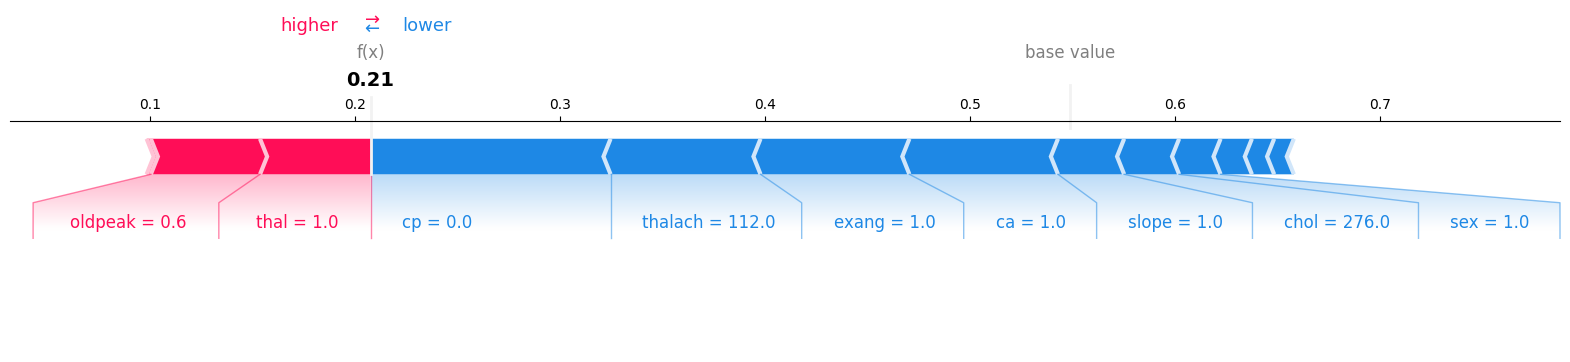

In [35]:

# Explain one test prediction

sample_index = 0

print("Actual class:", y_test.iloc[sample_index])
print("Predicted class:", rf_pred[sample_index])
print("Predicted probability for Class 1:", round(rf_prob[sample_index], 3))

shap.force_plot(
    explainer.expected_value[1],
    shap_values[sample_index, :, 1],
    X_test.iloc[sample_index],
    matplotlib=True
)

plt.show()


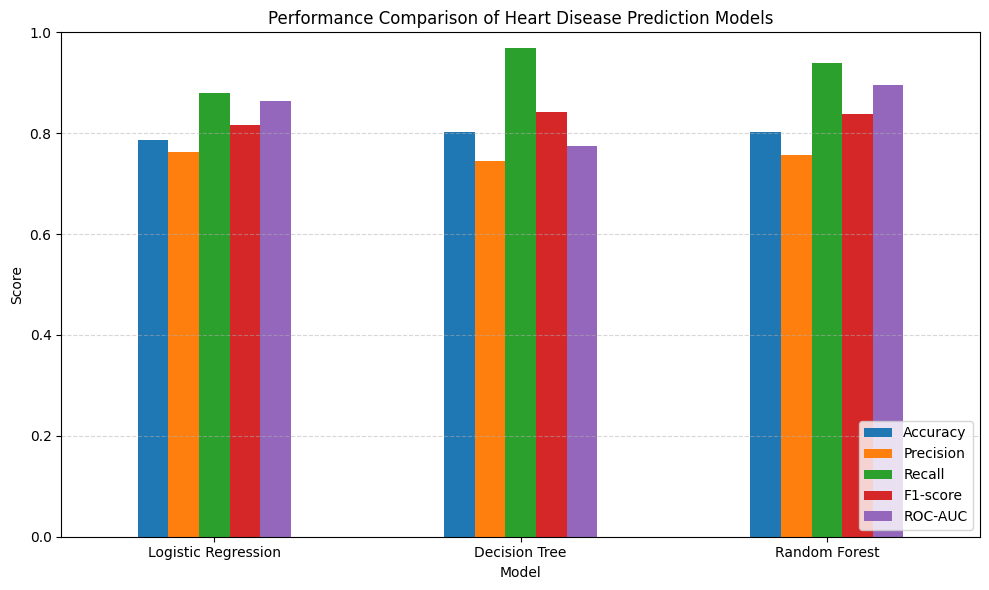

In [36]:

# Compare model performance

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Heart Disease Prediction Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [37]:

# Save model comparison results

results_df.to_csv(
    "heart_disease_model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

display(results_df.round(3))


Model comparison results saved successfully!


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.787,0.763,0.879,0.817,0.865
1,Decision Tree,0.803,0.744,0.970,0.842,0.775
2,Random Forest,0.803,0.756,0.939,0.838,0.895


In [38]:

from google.colab import files

files.download("heart_disease_model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>